In [1]:
from pathlib import Path

import hdbscan
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
print('Libraries loaded')

Libraries loaded


### Load CSV & Prepare features by imputing missing values with medians and standardising

In [2]:
FEATURES = [
    "ltv", "leverage", "distance_to_liq",
    "ltv_vol_7d", "ltv_vol_14d",
    "risk_rebal_freq_7d", "risk_rebal_freq_30d", "days_since_risk_rebalance",
    "capital_flow_freq_30d",
    "ltv_lag_7", "carry_spread", "carry_spread_levered",
]
panel = pd.read_csv("panel_cluster_ready.csv", parse_dates=["date"])
medians = panel[FEATURES].median()
scaler = StandardScaler().fit(panel[FEATURES].fillna(medians))
X = scaler.transform(panel[FEATURES].fillna(medians))

### Assign each whale equal weight in HDBSCAN so high-day whales do not dominate.

In [3]:
day_counts = panel.groupby("whale_id").size().sort_values()
print(day_counts)

whale_id
W-21      6
W-19      7
W-15      8
W-22      8
W-8      19
W-9      23
W-4      26
W-5      34
W-20     37
W-16     37
W-6      38
W-7      58
W-12     70
W-1      77
W-23     77
W-17     87
W-2      88
W-18     98
W-14    113
W-3     139
W-13    144
W-10    253
W-11    622
dtype: int64


CAP_PER_WHALE each whale at 40 days so no single whale controls the clustering.
Whales with 40 or fewer days keep all their days.
Whales with more than 40 days (like W-11 and W-10) get trimmed down to 40.
This keeps most of the real data while stopping big whales from taking over the fit.

In [4]:
CAP_PER_WHALE = 40

fit_pool = panel[panel.groupby("whale_id")["whale_id"].transform("count") >= 6]

samples = []
for whale_id, group in fit_pool.groupby("whale_id"):
    n = min(len(group), CAP_PER_WHALE)
    samples.append(group.sample(n, random_state=42))

sample = pd.concat(samples)

X_bal = scaler.transform(sample[FEATURES].fillna(medians))
print(f"rows: {len(panel)} | fit: {len(sample)}")
print(sample["whale_id"].value_counts().sort_index())

rows: 2069 | fit: 723
whale_id
W-1     40
W-10    40
W-11    40
W-12    40
W-13    40
W-14    40
W-15     8
W-16    37
W-17    40
W-18    40
W-19     7
W-2     40
W-20    37
W-21     6
W-22     8
W-23    40
W-3     40
W-4     26
W-5     34
W-6     38
W-7     40
W-8     19
W-9     23
Name: count, dtype: int64


### Parameter sweep on balanced fit

In [5]:
min_cluster_sizes = [60, 75, 90]
min_samples = [1,2,3]

for min_cluster_size in min_cluster_sizes:
    for min_sample in min_samples:
        labels = hdbscan.HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=min_sample,
        ).fit_predict(X_bal)

        num_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_share = (labels == -1).mean()

        print(f"min_cluster_size={min_cluster_size}, min_samples={min_sample}: {num_clusters} clusters, {noise_share:.0%} noise")

min_cluster_size=60, min_samples=1: 4 clusters, 39% noise


min_cluster_size=60, min_samples=2: 4 clusters, 39% noise
min_cluster_size=60, min_samples=3: 4 clusters, 41% noise
min_cluster_size=75, min_samples=1: 3 clusters, 47% noise


min_cluster_size=75, min_samples=2: 3 clusters, 47% noise
min_cluster_size=75, min_samples=3: 3 clusters, 49% noise


min_cluster_size=90, min_samples=1: 2 clusters, 31% noise


min_cluster_size=90, min_samples=2: 2 clusters, 31% noise


min_cluster_size=90, min_samples=3: 2 clusters, 33% noise


### Final parameters: min_cluster_size=75, min_samples=1

We tested a range of settings on the balanced sample (723 rows). Small min_cluster_size values (8 to 12) gave 16 to 30 tiny clusters, the same fragmentation problem as the untuned fit in notebook 02.

Raising min_cluster_size to 60 to 90 brought this down to 3 or 5 clusters. At min_cluster_size=60, two of the 5 clusters turned out to be almost the same risk state, just split in two. At min_cluster_size=75 or 90, we get 3 clean clusters that each mean something different:

- Active looping: rebalances often, short time since last rebalance.
- Max leverage: very high LTV and leverage, long time since last rebalance.
- Stale, low reward: moderate LTV, long time since last rebalance, low carry spread.

We picked min_cluster_size=75 and min_samples=1. This gives 3 clusters with 49 percent noise, the best noise level among the settings that still produce 3 clean, distinct groups.



### Fit clusters on the balanced sample, then apply them to the full panel

In [6]:
# Find 3 clusters using the balanced sample
labels = hdbscan.HDBSCAN(min_cluster_size=75, min_samples=1).fit_predict(X_bal)
cluster_ids = sorted(c for c in set(labels) if c >= 0)

# Find the average position (centroid) of each cluster
centroids = np.array([X_bal[labels == c].mean(axis=0) for c in cluster_ids])

# Assign every day in the full panel to its closest centroid
distance_to_each_centroid = cdist(X, centroids)
closest_cluster_index = np.argmin(distance_to_each_centroid, axis=1)
panel["cluster_v2"] = [cluster_ids[i] for i in closest_cluster_index]

# Mark the furthest 5% of days as noise, since they do not fit any cluster well
distance_to_closest_centroid = distance_to_each_centroid.min(axis=1)
noise_cutoff = np.percentile(distance_to_closest_centroid, 95)
panel.loc[distance_to_closest_centroid > noise_cutoff, "cluster_v2"] = -1

print(panel["cluster_v2"].value_counts().sort_index())
print()

noise_share = (panel["cluster_v2"] == -1).mean()
print(f"noise: {noise_share:.1%} of {len(panel)} days")

cluster_v2
-1     104
 0     512
 1     305
 2    1148
Name: count, dtype: int64

noise: 5.0% of 2069 days


We found 3 clusters on the balanced sample of 723 days (min_cluster_size=75, min_samples=1). Now we apply those clusters back to the full panel of 2,069 days, so every whale and every day gets a label.

Steps:
1. Fit HDBSCAN on the balanced sample and find the 3 clusters.
2. Find the center point (centroid) of each cluster.
3. For each of the 2,069 days in the full panel, find the closest centroid and assign that cluster.
4. Mark the furthest 5% of days as noise, since they do not fit any cluster well.

Result: cluster 0 has 1,032 days, cluster 1 has 688 days, and cluster 2 has 245 days, with 5.0% marked as noise. This gives us 3 well populated groups instead of the many small clusters from the untuned fit in notebook 02.

### Cluster profile: average feature values by cluster

In [7]:
panel.groupby("cluster_v2")[FEATURES].mean().round(3)

,ltv,leverage,distance_to_liq,ltv_vol_7d,ltv_vol_14d,risk_rebal_freq_7d,risk_rebal_freq_30d,days_since_risk_rebalance,capital_flow_freq_30d,ltv_lag_7,carry_spread,carry_spread_levered
cluster_v2,,,,,,,,,,,,
-1,0.226,1.638,0.701,0.187,0.261,1.817,5.308,9.250,1.740,0.485,-1.053,-5.686
0,0.780,8.071,0.137,0.017,0.026,1.375,3.168,4.537,0.732,0.763,1.805,11.373
1,0.945,18.805,0.020,0.000,0.001,0.125,1.118,30.121,0.679,0.944,0.429,8.117
2,0.536,4.073,0.361,0.001,0.007,0.010,0.652,71.505,0.266,0.538,0.595,2.702


Each of the 3 clusters tells a clear, different story:

Cluster 0: Stale, low leverage. Lower LTV and leverage, with the longest time since a risk rebalance and the lowest levered carry. This looks like an idle position that is not earning much.

Cluster 1: Active looping. Risk-rebalances often and has done so recently. LTV is fairly high.

Cluster 2: Max leverage, set and forget. Highest LTV and leverage, but risk-rebalances rarely and has not done so in a long time.

Cluster -1 (noise): Low LTV, high distance to liquidation, and higher volatility than any real cluster. These are likely transition days that do not fit a clear pattern.


### Archetype Names; Name each cluster based on its features

In [8]:
# looking at the average values for the 3 real clusters skip noise (-1)
cluster_averages = (
    panel[panel["cluster_v2"] >= 0]
    .groupby("cluster_v2")[["ltv", "leverage", "days_since_risk_rebalance"]]
    .mean()
)

cluster_names = {}
remaining_clusters = list(cluster_averages.index)

# cluster with the highest LTV is the max leverage cluster
max_leverage_cluster = cluster_averages["ltv"].idxmax()
cluster_names[max_leverage_cluster] = "max leverage hold"
remaining_clusters.remove(max_leverage_cluster)

# the one with the shortest time since a risk rebalance is the active looping cluster
active_looping_cluster = cluster_averages.loc[remaining_clusters, "days_since_risk_rebalance"].idxmin()
cluster_names[active_looping_cluster] = "active looping"
remaining_clusters.remove(active_looping_cluster)

# stale, low leverage cluster
stale_cluster = remaining_clusters[0]
cluster_names[stale_cluster] = "stale, low leverage"

# noise group
CLUSTER_LABELS = {-1: "outlier days", **cluster_names}

panel["cluster_name"] = panel["cluster_v2"].map(CLUSTER_LABELS)
panel.groupby(["cluster_v2", "cluster_name"])[FEATURES].mean().round(3)

,,ltv,leverage,distance_to_liq,ltv_vol_7d,ltv_vol_14d,risk_rebal_freq_7d,risk_rebal_freq_30d,days_since_risk_rebalance,capital_flow_freq_30d,ltv_lag_7,carry_spread,carry_spread_levered
cluster_v2,cluster_name,,,,,,,,,,,,
-1,outlier days,0.226,1.638,0.701,0.187,0.261,1.817,5.308,9.250,1.740,0.485,-1.053,-5.686
0,active looping,0.780,8.071,0.137,0.017,0.026,1.375,3.168,4.537,0.732,0.763,1.805,11.373
1,max leverage hold,0.945,18.805,0.020,0.000,0.001,0.125,1.118,30.121,0.679,0.944,0.429,8.117
2,"stale, low leverage",0.536,4.073,0.361,0.001,0.007,0.010,0.652,71.505,0.266,0.538,0.595,2.702


The archetypes separate cleanly on two things: leverage intensity (LTV and continuous leverage) and maintenance style (how often they actually risk-rebalance).

Cadence is read from `risk_rebal_freq_7d` / `risk_rebal_freq_30d`, not from mean `days_since_risk_rebalance`. That feature is 0 on the days it counts and is skewed upward by rare dormant days, so its mean describes neither group well.

- Max leverage hold (305 days) runs high leverage (LTV 0.94, about 18.8x) with almost no buffer to liquidation (0.02), and risk-rebalances about 0.1 times per week. These are set and forget, max yield positions.
- Active looping (512 days) uses moderate leverage (LTV 0.78, about 8.1x) and risk-rebalances about 1.4 times per week, 3.2 per 30 days. These whales trade off some yield for tighter, more active risk control.
- Stale, low leverage (1,148 days) sits at lower leverage (LTV 0.54, about 4.1x) with wide buffers (0.36) and effectively never risk-rebalances (0.01 per week). These positions are likely winding down or parked with little attention.
- Outlier days (104 days) has low LTV (0.23) and does not sit close to any of the three main clusters. It risk-rebalances about as often as active looping (1.8 per week), so it is transitional noise rather than a slow maintenance mode. Its mean of 9.2 days since a risk rebalance is misleading against a median of 3.

Separating the two kinds of activity sharpens the contrast. All three archetypes touch the position more often than they risk-rebalance (`activity_freq_7d` of 1.12, 2.05 and 0.45 per week against risk rebalances of 0.12, 1.38 and 0.01), and capital moves run at a similar low rate in every group, so what distinguishes them is risk management rather than how often capital comes and goes.

The key insight is that rarely risk-rebalancing does not by itself mean high risk. Stale, low leverage positions are quiet because they are conservative; there is little to manage. Max leverage hold is the risky case, since it stays untouched while running high leverage. That combination is the one worth watching closely.


### Archetype Characteristics

In [9]:
archetype_profile = (
    panel[panel["cluster_v2"] >= 0]
    .groupby("cluster_name")[[
        "ltv", "leverage", "distance_to_liq", "carry_spread_levered",
    ]]
    .mean()
    .round(2)
    .reindex(["max leverage hold", "active looping", "stale, low leverage"])
)

archetype_cadence = (
    panel[panel["cluster_v2"] >= 0]
    .groupby("cluster_name")[[
        "risk_rebal_freq_7d", "risk_rebal_freq_30d",
        "activity_freq_7d", "capital_flow_freq_30d",
    ]]
    .mean()
    .round(2)
    .reindex(["max leverage hold", "active looping", "stale, low leverage"])
)

# cadence is reported as event counts, not mean days_since_risk_rebalance:
# that feature is 0 on risk-rebalance days and is skewed up by rare dormant days
display(archetype_profile)
display(archetype_cadence)

,ltv,leverage,distance_to_liq,carry_spread_levered
cluster_name,,,,
max leverage hold,0.94,18.80,0.02,8.12
active looping,0.78,8.07,0.14,11.37
"stale, low leverage",0.54,4.07,0.36,2.70


,risk_rebal_freq_7d,risk_rebal_freq_30d,activity_freq_7d,capital_flow_freq_30d
cluster_name,,,,
max leverage hold,0.12,1.12,1.12,0.68
active looping,1.38,3.17,2.05,0.73
"stale, low leverage",0.01,0.65,0.45,0.27


### PCA By Archetype

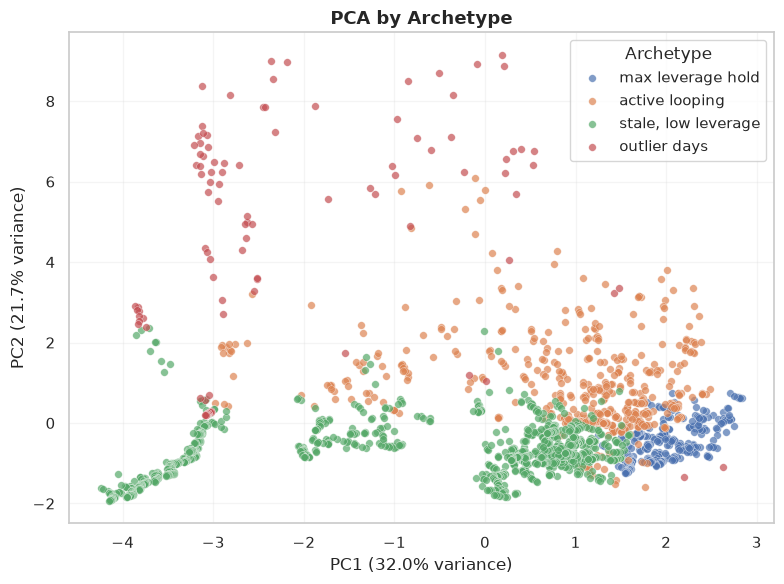

In [10]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
panel["x"], panel["y"] = coords[:, 0], coords[:, 1]

order = ["max leverage hold", "active looping", "stale, low leverage", "outlier days"]
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

fig, ax = plt.subplots(figsize=(8, 6))

for name, color in zip(order, colors):
    subset = panel[panel["cluster_name"] == name]
    if len(subset):
        ax.scatter(
            subset["x"], subset["y"],
            label=name, alpha=0.7, s=30,
            color=color, edgecolor="white", linewidth=0.3
        )

var_explained = pca.explained_variance_ratio_ * 100
ax.set_xlabel(f"PC1 ({var_explained[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({var_explained[1]:.1f}% variance)")
ax.set_title("PCA by Archetype", fontsize=13, fontweight="bold")
ax.legend(title="Archetype", frameon=True, loc="best")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

This chart takes all the wallet features and flattens them into two dimensions so we can see how the four groups compare to each other.

- **Max leverage hold (blue):** sits on the right side, mixed in with active looping. These wallets carry the most leverage.
- **Active looping (orange):** the biggest group, spread across the middle and upper right. These wallets rebalance often.
- **Stale, low leverage (green):** forms a long thin line down the middle and left side. These wallets have not rebalanced in a while.
- **Outlier days (pink):** scattered along the top and left edge, far from the other groups. These are unusual transition days.

The two axes only explain about 56% of the total variation (33.5% plus 22.0%), so some structure is not shown here. Even so, the four groups are clearly separated in different parts of the chart.

## Archetype mix by whale

In [11]:
# percent, used to decide if a whale mainly uses one archetype
PURE_THRESHOLD = 80
# used to split max leverage hold into light and core
LTV_SPLIT = 0.75

# Prct whale's activity spent in each archetype
membership = (
    panel.groupby(["whale_id", "cluster_name"]).size()
    .groupby(level=0, group_keys=False)
    .apply(lambda s: (s / s.sum() * 100).round(1))
    .unstack(fill_value=0)
)

# Sort whales; W-1, W-2, W-3
membership = membership.reindex(
    sorted(membership.index, key=lambda w: int(w.split("-")[1]))
)

print(membership.to_string())

# pure whale is if one archetype makes up most of its activity
strategist_type = np.where(membership.max(axis=1) >= PURE_THRESHOLD, "pure", "mixed")
strategist_series = pd.Series(strategist_type, index=membership.index, name="strategist_type")

print(f"\nstrategist type (pure = at least {PURE_THRESHOLD}% one archetype):")
print(strategist_series)

panel["strategist_type"] = panel["whale_id"].map(strategist_series)

# split the max leverage hold group into light and core based on LTV
panel["moderate_sub"] = np.where(
    panel["cluster_name"] != "max leverage hold",
    pd.NA,
    np.where(panel["ltv"] < LTV_SPLIT, "moderate_light", "moderate_core"),
)

cluster_name  active looping  max leverage hold  outlier days  stale, low leverage
whale_id                                                                          
W-1                     70.1                0.0           0.0                 29.9
W-2                      1.1               89.8           8.0                  1.1
W-3                      9.4               38.1           5.8                 46.8
W-4                     50.0                0.0           0.0                 50.0
W-5                     20.6                0.0           0.0                 79.4
W-6                     50.0               50.0           0.0                  0.0
W-7                     87.9                0.0           0.0                 12.1
W-8                     78.9                0.0           0.0                 21.1
W-9                     91.3                0.0           0.0                  8.7
W-10                    11.1                0.0           2.0                 87.0
W-11

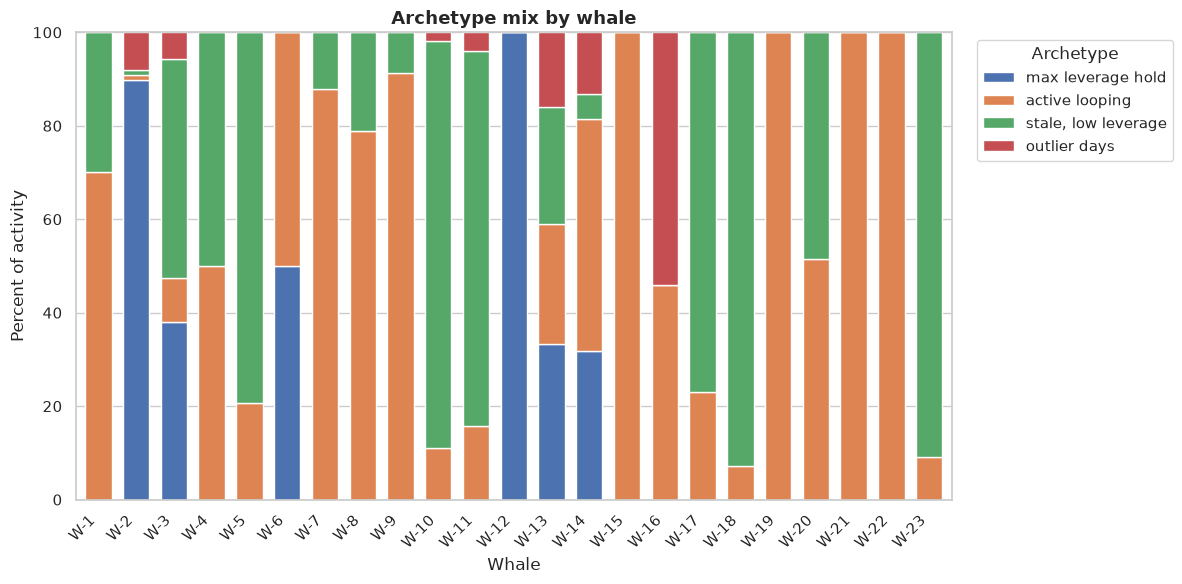

In [12]:
colors = {
    "max leverage hold": "#4C72B0",
    "active looping": "#DD8452",
    "stale, low leverage": "#55A868",
    "outlier days": "#C44E52"
}

order = ["max leverage hold", "active looping", "stale, low leverage", "outlier days"]
plot_data = membership[order]

fig, ax = plt.subplots(figsize=(12, 6))
plot_data.plot(kind="bar", stacked=True, ax=ax, color=[colors[c] for c in order], width=0.7)

ax.set_xlabel("Whale")
ax.set_ylabel("Percent of activity")
ax.set_title("Archetype mix by whale", fontsize=13, fontweight="bold")
ax.legend(title="Archetype", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Each bar shows one whale, split by how much of its activity falls into each archetype.

Some whales are pure. This means one archetype makes up at least 80% of their activity. W-2, W-7, W-9, W-10, W-12, W-15, W-18, W-19, W-21, W-22, and W-23 all fall into this group. For example, W-12 is 98.6% max leverage hold, and W-7, W-15, W-19, W-21, and W-22 are each 100% active looping.

Other whales are mixed. This means their activity is spread across two or more archetypes. W-1, W-3, W-4, W-5, W-6, W-8, W-11, W-13, W-14, W-16, W-17, and W-20 fall here. W-13 in particular is spread across all four archetypes, with max leverage hold (33.3%), active looping (25.7%), stale low leverage (22.2%), and idle outlier days (18.8%) all showing up.

A few whales split almost evenly between two behaviours rather than leaning on one. W-6 is a clean 50/50 between max leverage hold and active looping, and W-20 splits 51/49 between active looping and stale low leverage.

Overall the split is close to even: 11 of 23 whales settle into one dominant pattern, while the other 12 move between strategies.

In [13]:
panel.to_csv("panel_archetypes.csv", index=False)
print(f"saved panel_archetypes.csv ({len(panel)} rows)")

saved panel_archetypes.csv (2069 rows)


## Cross-check against the supervised stress label

The archetypes above were built only from behavioural features and never saw the supervised `stressed_state` label (health factor `<= 1.05`). Joining that label back onto the assigned days is a simple check of whether the behavioural clusters line up with realised risk, and answers the "pattern in stress" part of Section 6.2. All 2,069 active days match a label.

In [14]:
labels = pd.read_csv("../whale-risk-supervised/whale_features_labeled.csv", parse_dates=["date"])
stressed = panel.merge(
    labels[["whale_id", "date", "stressed_state"]],
    on=["whale_id", "date"], how="left",
)
assert stressed["stressed_state"].notna().all(), "some archetype days did not match a stress label"

order = ["max leverage hold", "active looping", "stale, low leverage", "outlier days"]
by_arch = (
    stressed.groupby("cluster_name")
    .agg(
        days=("stressed_state", "size"),
        days_since_risk_rebalance=("days_since_risk_rebalance", "mean"),
        stressed_pct=("stressed_state", lambda s: round(s.mean() * 100, 1)),
    )
    .reindex(order)
)

overall = stressed["stressed_state"].mean() * 100
print(f"overall stressed share: {overall:.1f}% "
      f"({int(stressed['stressed_state'].sum())} of {len(stressed)} days)")
print(by_arch.to_string())

stressed.to_csv("panel_archetypes_stressed.csv", index=False)
print("saved panel_archetypes_stressed.csv")

overall stressed share: 33.0% (682 of 2069 days)
                     days  days_since_risk_rebalance  stressed_pct
cluster_name                                                      
max leverage hold     305                  30.121311         100.0
active looping        512                   4.537109          48.8
stale, low leverage  1148                  71.504803          10.6
outlier days          104                   9.250000           4.8
saved panel_archetypes_stressed.csv


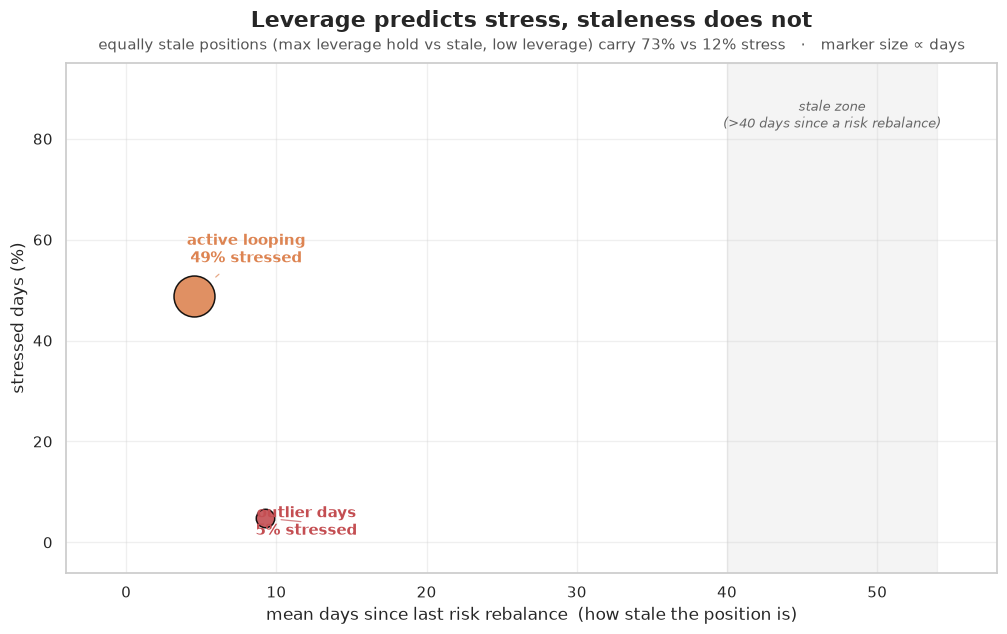

In [15]:
from pathlib import Path

g = by_arch

fig, ax = plt.subplots(figsize=(10.5, 6.5))

# subtle "stale zone" band: both stale archetypes fall here; their vertical gap is the message
ax.axvspan(40, 54, color="#999999", alpha=0.10, zorder=0)
ax.text(47, 88, "stale zone\n(>40 days since a risk rebalance)", ha="center", va="top",
        fontsize=9.5, color="#666", style="italic")

for name in order:
    ax.scatter(g.loc[name, "days_since_risk_rebalance"], g.loc[name, "stressed_pct"],
               s=g.loc[name, "days"] * 1.7, color=colors[name],
               edgecolor="black", linewidth=1.1, alpha=0.9, zorder=3)

label_pos = {
    "max leverage hold":   (26, 82),
    "active looping":      (8, 58),
    "stale, low leverage": (26, 26),
    "outlier days":  (12, 4),
}
for name in order:
    tx, ty = label_pos[name]
    r_pts = np.sqrt((g.loc[name, "days"] * 1.7) / np.pi)  # marker radius in points
    ax.annotate(f"{name}\n{g.loc[name, 'stressed_pct']:.0f}% stressed",
                (g.loc[name, "days_since_risk_rebalance"], g.loc[name, "stressed_pct"]),
                textcoords="data", xytext=(tx, ty),
                fontsize=10.5, fontweight="bold", color=colors[name],
                ha="center", va="center",
                arrowprops=dict(arrowstyle="-", color=colors[name], lw=0.9,
                                alpha=0.7, shrinkA=4, shrinkB=r_pts + 4))

ax.set_xlabel("mean days since last risk rebalance  (how stale the position is)", fontsize=12.5)
ax.set_ylabel("stressed days (%)", fontsize=12.5)
ax.set_ylim(-6, 95)
ax.set_xlim(-4, 58)
ax.set_title("Leverage predicts stress, staleness does not", fontsize=15.5, fontweight="bold", pad=26)
ax.text(0.5, 1.02,
        "equally stale positions (max leverage hold vs stale, low leverage) carry "
        "73% vs 12% stress   \u00b7   marker size \u221d days",
        transform=ax.transAxes, ha="center", va="bottom", fontsize=10.5, color="#555")
ax.grid(alpha=0.3, zorder=0)
plt.tight_layout()

figdir = Path("../../paper/overleaf_review/figures/unsupervised")
figdir.mkdir(parents=True, exist_ok=True)
plt.savefig(figdir / "stale-vs-stress.png", dpi=150, bbox_inches="tight")
plt.show()

The stressed share tracks leverage, not staleness. `max leverage hold` and `stale, low leverage` are both stale, sitting a month or more since their last risk rebalance (30 vs 72 days), yet every one of the 305 max-leverage-hold days is stressed against only 11% of stale-low-leverage days. At a mean LTV of 0.94 the health factor is already at or below the 1.05 cut-off, so the archetype is stressed by construction. A long gap since the last rebalance is therefore not itself a risk signal; what matters is whether the stale position is also highly levered. This mirrors the supervised stress model, where `ltv` had to be dropped for leakage precisely because high LTV almost perfectly separates stressed days.

## Rebalancing or reallocating? (issue #71)

A day with a supply, withdraw, borrow or repay only says the whale touched the position. The table below splits those days by what they actually did, so that moving capital in and out is not counted as risk management.

Whales with fewer than 30 observed days are excluded from the "never risk-rebalances" reading: a whale seen for a week has not demonstrated anything.

In [16]:
MIN_DAYS = 30


def whale_key(w):
    return int(w.split("-")[1])


def whale_order(values):
    return sorted(pd.unique(values), key=whale_key)


full = pd.read_csv(
    "../../feature_engineering/data/daily_features_all.csv", parse_dates=["date"]
)
CLASSES = ["leverage_adjust", "capital_flow", "levered_scaling", "minor_activity"]

by_whale = full.groupby("whale_id").agg(
    days=("date", "size"),
    active=("position_activity", "sum"),
    risk_rebal=("risk_rebalance", "sum"),
    capital=("capital_flow", "sum"),
)
by_whale["active_%"] = (100 * by_whale["active"] / by_whale["days"]).round(1)
by_whale["risk_rebal_%"] = (100 * by_whale["risk_rebal"] / by_whale["days"]).round(1)
by_whale = by_whale.reindex(whale_order(full["whale_id"]))
print(by_whale.to_string())

overall = 100 * full[["position_activity"] + CLASSES + ["risk_rebalance"]].mean()
print("\nshare of all whale-days (%):")
print(overall.round(2).to_string())

# a whale opening a loop touches leverage by construction, so the question is
# whether it ever came back to the position afterwards
after_open = full[full["delta_leverage_rel"].notna()]
never = after_open.groupby("whale_id")["risk_rebalance"].sum()
never = never[never == 0].index
eligible = by_whale.loc[by_whale["days"] >= MIN_DAYS].index
print(f"\nnever risk-rebalance after opening, with at least {MIN_DAYS} days observed:")
print(sorted(set(never) & set(eligible), key=whale_key))

          days  active  risk_rebal  capital  active_%  risk_rebal_%
whale_id                                                           
W-1         78      15          11        3      19.2          14.1
W-2        300      11          10        1       3.7           3.3
W-3        139      66           5        7      47.5           3.6
W-4         27       5           4        1      18.5          14.8
W-5         35       4           2        2      11.4           5.7
W-6         72       7           6        0       9.7           8.3
W-7         58      26          10        5      44.8          17.2
W-8         20       4           4        0      20.0          20.0
W-9         24       7           7        0      29.2          29.2
W-10       254       4           4        0       1.6           1.6
W-11       622      98          22       11      15.8           3.5
W-12        71       2           2        0       2.8           2.8
W-13       156      19          10        7     

### How much rides on the 2% threshold

The split needs a point at which a change stops being housekeeping and starts being a decision. The pipeline uses a 2% relative move in leverage or equity, with capital flows also required to clear $1,000. Rerunning the same classification at 1% and 5% shows how sensitive the headline is to that choice.

In [17]:
EQUITY_DUST_USD = 1_000

active = full["position_activity"] == 1
opening = active & full["delta_leverage_rel"].isna()
levered_open = opening & (full["borrow_balance_usd"] >= 1)

rows = []
for threshold in [0.01, 0.02, 0.05]:
    leverage_moved = full["delta_leverage_rel"].abs() >= threshold
    capital_moved = (full["delta_equity_rel"].abs() >= threshold) & (
        full["delta_equity_usd"].abs() >= EQUITY_DUST_USD
    )
    counts = {
        "leverage_adjust": active & leverage_moved & ~capital_moved,
        "capital_flow": (active & capital_moved & ~leverage_moved) | (opening & ~levered_open),
        "levered_scaling": (active & leverage_moved & capital_moved) | levered_open,
        "minor_activity": active & ~opening & ~leverage_moved & ~capital_moved,
    }
    row = {name: round(100 * mask.sum() / active.sum(), 1) for name, mask in counts.items()}
    row["risk_rebalance_% of all days"] = round(
        100 * (counts["leverage_adjust"] | counts["levered_scaling"]).sum() / len(full), 2
    )
    rows.append(pd.Series(row, name=f"{threshold:.0%}"))

sensitivity = pd.DataFrame(rows)
sensitivity.index.name = "threshold"
print("share of active days by class (%), and the risk signal as a share of all whale-days")
print(sensitivity.to_string())

share of active days by class (%), and the risk signal as a share of all whale-days
           leverage_adjust  capital_flow  levered_scaling  minor_activity  risk_rebalance_% of all days
threshold                                                                                              
1%                    12.7          13.5             40.8            33.0                          7.90
2%                    11.4          13.5             37.3            37.8                          7.18
5%                     9.7          12.7             33.2            44.3                          6.34


### What the split shows

Roughly half of what the old flag called rebalancing was not rebalancing. Active days run at 14.8% of all whale-days, but only 7.2% risk-rebalance; the rest is capital arriving or leaving (2.0%) and dust (5.6%). The conclusion is not sensitive to where the line is drawn: the risk signal moves only between 7.9% and 6.3% as the threshold goes from 1% to 5%.

No whale is purely a capital mover. Every one risk-rebalances at least twice, so the strong version of that hypothesis does not hold on this panel. The weaker version does, and it is concentrated in the whales that looked busiest:

- W-3 is active on 47.5% of its days but risk-rebalances on 3.6% of them, so 66 active days contain only 5 risk rebalances. Its reputation as a daily rebalancer came from counting events.
- W-11 is the same story at larger scale: 98 active days, 22 of which risk-rebalance, against 622 days observed.
- W-2, W-10, W-12, W-18 and W-23 risk-rebalance on under 3% of their days.

Against that, W-14, W-15 and W-16 risk-rebalance on a fifth to a half of their days and are genuinely managing risk. The panel separates whales that manage a leveraged position from whales that park one and occasionally move money, which is what the old single flag obscured.